# Day 6 · Vintage — A surface pressure analysis
### #30DayMapChallenge 2026 · ECMWF open data · Map by Emma Pidduck

Modern data, old clothes. This is **today's mean-sea-level pressure** drawn as a mid-century
**surface analysis chart** — sepia ink on aged paper, labelled isobars every 4 hPa, and the
**H**/**L** pressure centres marked by hand the way the Met Office did before computers drew
the lines. The numbers are live from the ECMWF IFS; only the *styling* is 1950s.

Self-contained: method, code, output, data licence and tools in one place.

## Method

- Fetch **mean sea-level pressure** (`msl`) and convert Pa → hPa.
- **Smooth** lightly (Gaussian, σ≈2 grid cells) so the isobars read as clean, hand-drawn
  curves rather than wiggly model contours.
- **Contour** every 4 hPa with inline labels — the classic isobar interval.
- **Find the pressure centres** as local maxima/minima of the smoothed field (a
  `maximum_filter`/`minimum_filter` neighbourhood test) and mark each **H**/**L** with its
  central pressure, as an analyst would.
- Dress it: aged-paper background with a little grain and a vignette, a serif typeface
  (Baskerville), a ruled double border, and a plate title.

A deliberate departure from the series' white-background house style — but still accessible:
a monochrome ink-on-paper chart is read by **luminance alone**, so it is colourblind-safe by
construction. *Fronts are left off on purpose* — honest automated frontal analysis is a
project in itself, and a wrong front is worse than none.

## Licence & attribution

Access to ECMWF Open Data is governed by the **Creative Commons CC-BY-4.0** licence and the
associated [Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

> In applying this licence, ECMWF does not waive the privileges and immunities granted to it
> by virtue of its status as an intergovernmental organisation.

`© ECMWF · Source: www.ecmwf.int · Licence: CC-BY-4.0 and ECMWF Terms of Use`

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve IFS open data |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read the GRIB |
| `scipy.ndimage` | smoothing + the local-extrema test for H/L centres |
| `cartopy` · `matplotlib` | projection, coastline, the vintage render |

MSLP is smooth and synoptic, so the default **0.25°** grid is plenty — no need for `0p1` here.

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata earthkit-data cfgrib xarray scipy cartopy matplotlib

In [2]:
import os, sys, io, contextlib
import numpy as np
import xarray as xr
import earthkit.data as ekd
from ecmwf.opendata import Client
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.ndimage import gaussian_filter, maximum_filter, minimum_filter
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# vintage palette: sepia ink on aged paper
PAPER, INK, FAINT, COAST = "#ece0c6", "#40321d", "#a8966f", "#6a5536"
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"]  = ["Baskerville", "Hoefler Text", "Palatino", "Times New Roman", "DejaVu Serif"]

@contextlib.contextmanager
def quiet():
    """Silence the open-data banner + download progress. Real errors still raise."""
    py = sys.stderr; sys.stderr = io.StringIO()
    try:
        saved = os.dup(2); dn = os.open(os.devnull, os.O_WRONLY); os.dup2(dn, 2)
    except Exception:
        saved = None
    try:
        yield
    finally:
        sys.stderr = py
        if saved is not None:
            os.dup2(saved, 2); os.close(saved); os.close(dn)

### Configuration

`DATE = 0` uses **today's** 00Z run, so re-running on **6 November 2026** draws that morning's
chart. Pin a day with e.g. `DATE = "20261106"`.

In [3]:
DATE, TIME, STEP = 0, 0, 0
REGION = [-45, 25, 33, 70]                 # W, E, S, N — the classic Atlantic-Europe chart
EXTENT = [-38, 20, 35, 68]
GRIB   = "data/day06_msl.grib2"

## Retrieve

In [4]:
os.makedirs("data", exist_ok=True)
with quiet():
    if not os.path.exists(GRIB):
        Client("ecmwf").retrieve(date=DATE, time=TIME, step=STEP, stream="oper", type="fc",
            levtype="sfc", param="msl", target=GRIB)

## Read, tidy & smooth

In [5]:
x = ekd.from_source("file", GRIB).to_xarray().squeeze()
lon = x["longitude"].values.copy(); lat = x["latitude"].values.copy()
msl = x["msl"].values / 100.0                       # Pa -> hPa
lon = ((lon + 180) % 360) - 180
o = np.argsort(lon); lon, msl = lon[o], msl[:, o]
if lat[0] > lat[-1]: lat, msl = lat[::-1], msl[::-1]
mx = (lon >= REGION[0]-5) & (lon <= REGION[1]+5); my = (lat >= REGION[2]-5) & (lat <= REGION[3]+5)
lon, lat, msl = lon[mx], lat[my], msl[np.ix_(my, mx)]
msl = gaussian_filter(msl, sigma=2.0)               # clean, hand-drawn-looking isobars

VALID = str(xr.open_dataset(GRIB, engine="cfgrib")["valid_time"].values)[:16].replace("T", " ") + " UTC"
print(f"grid {msl.shape}  MSLP {msl.min():.0f}-{msl.max():.0f} hPa  valid {VALID}")

grid (189, 321)  MSLP 966-1029 hPa  valid 2026-10-28 00:00 UTC


## Find the pressure centres

A grid point is a **high** if it is the maximum within a ~7° neighbourhood, a **low** if it is
the minimum. We keep only centres a few degrees inside the frame so labels don't collide with
the border.

In [6]:
LO, LA = np.meshgrid(lon, lat)
sz = 28                                             # ~7 deg neighbourhood at 0.25 deg
hi = (maximum_filter(msl, size=sz) == msl); lo_ = (minimum_filter(msl, size=sz) == msl)
inner = (LO >= REGION[0]+3) & (LO <= REGION[1]-3) & (LA >= REGION[2]+3) & (LA <= REGION[3]-3)
def centres(mask):
    r, c = np.where(mask & inner); return [(LO[i, j], LA[i, j], msl[i, j]) for i, j in zip(r, c)]
highs, lows = centres(hi), centres(lo_)
print(f"{len(highs)} highs, {len(lows)} lows")

2 highs, 4 lows


## Render the chart

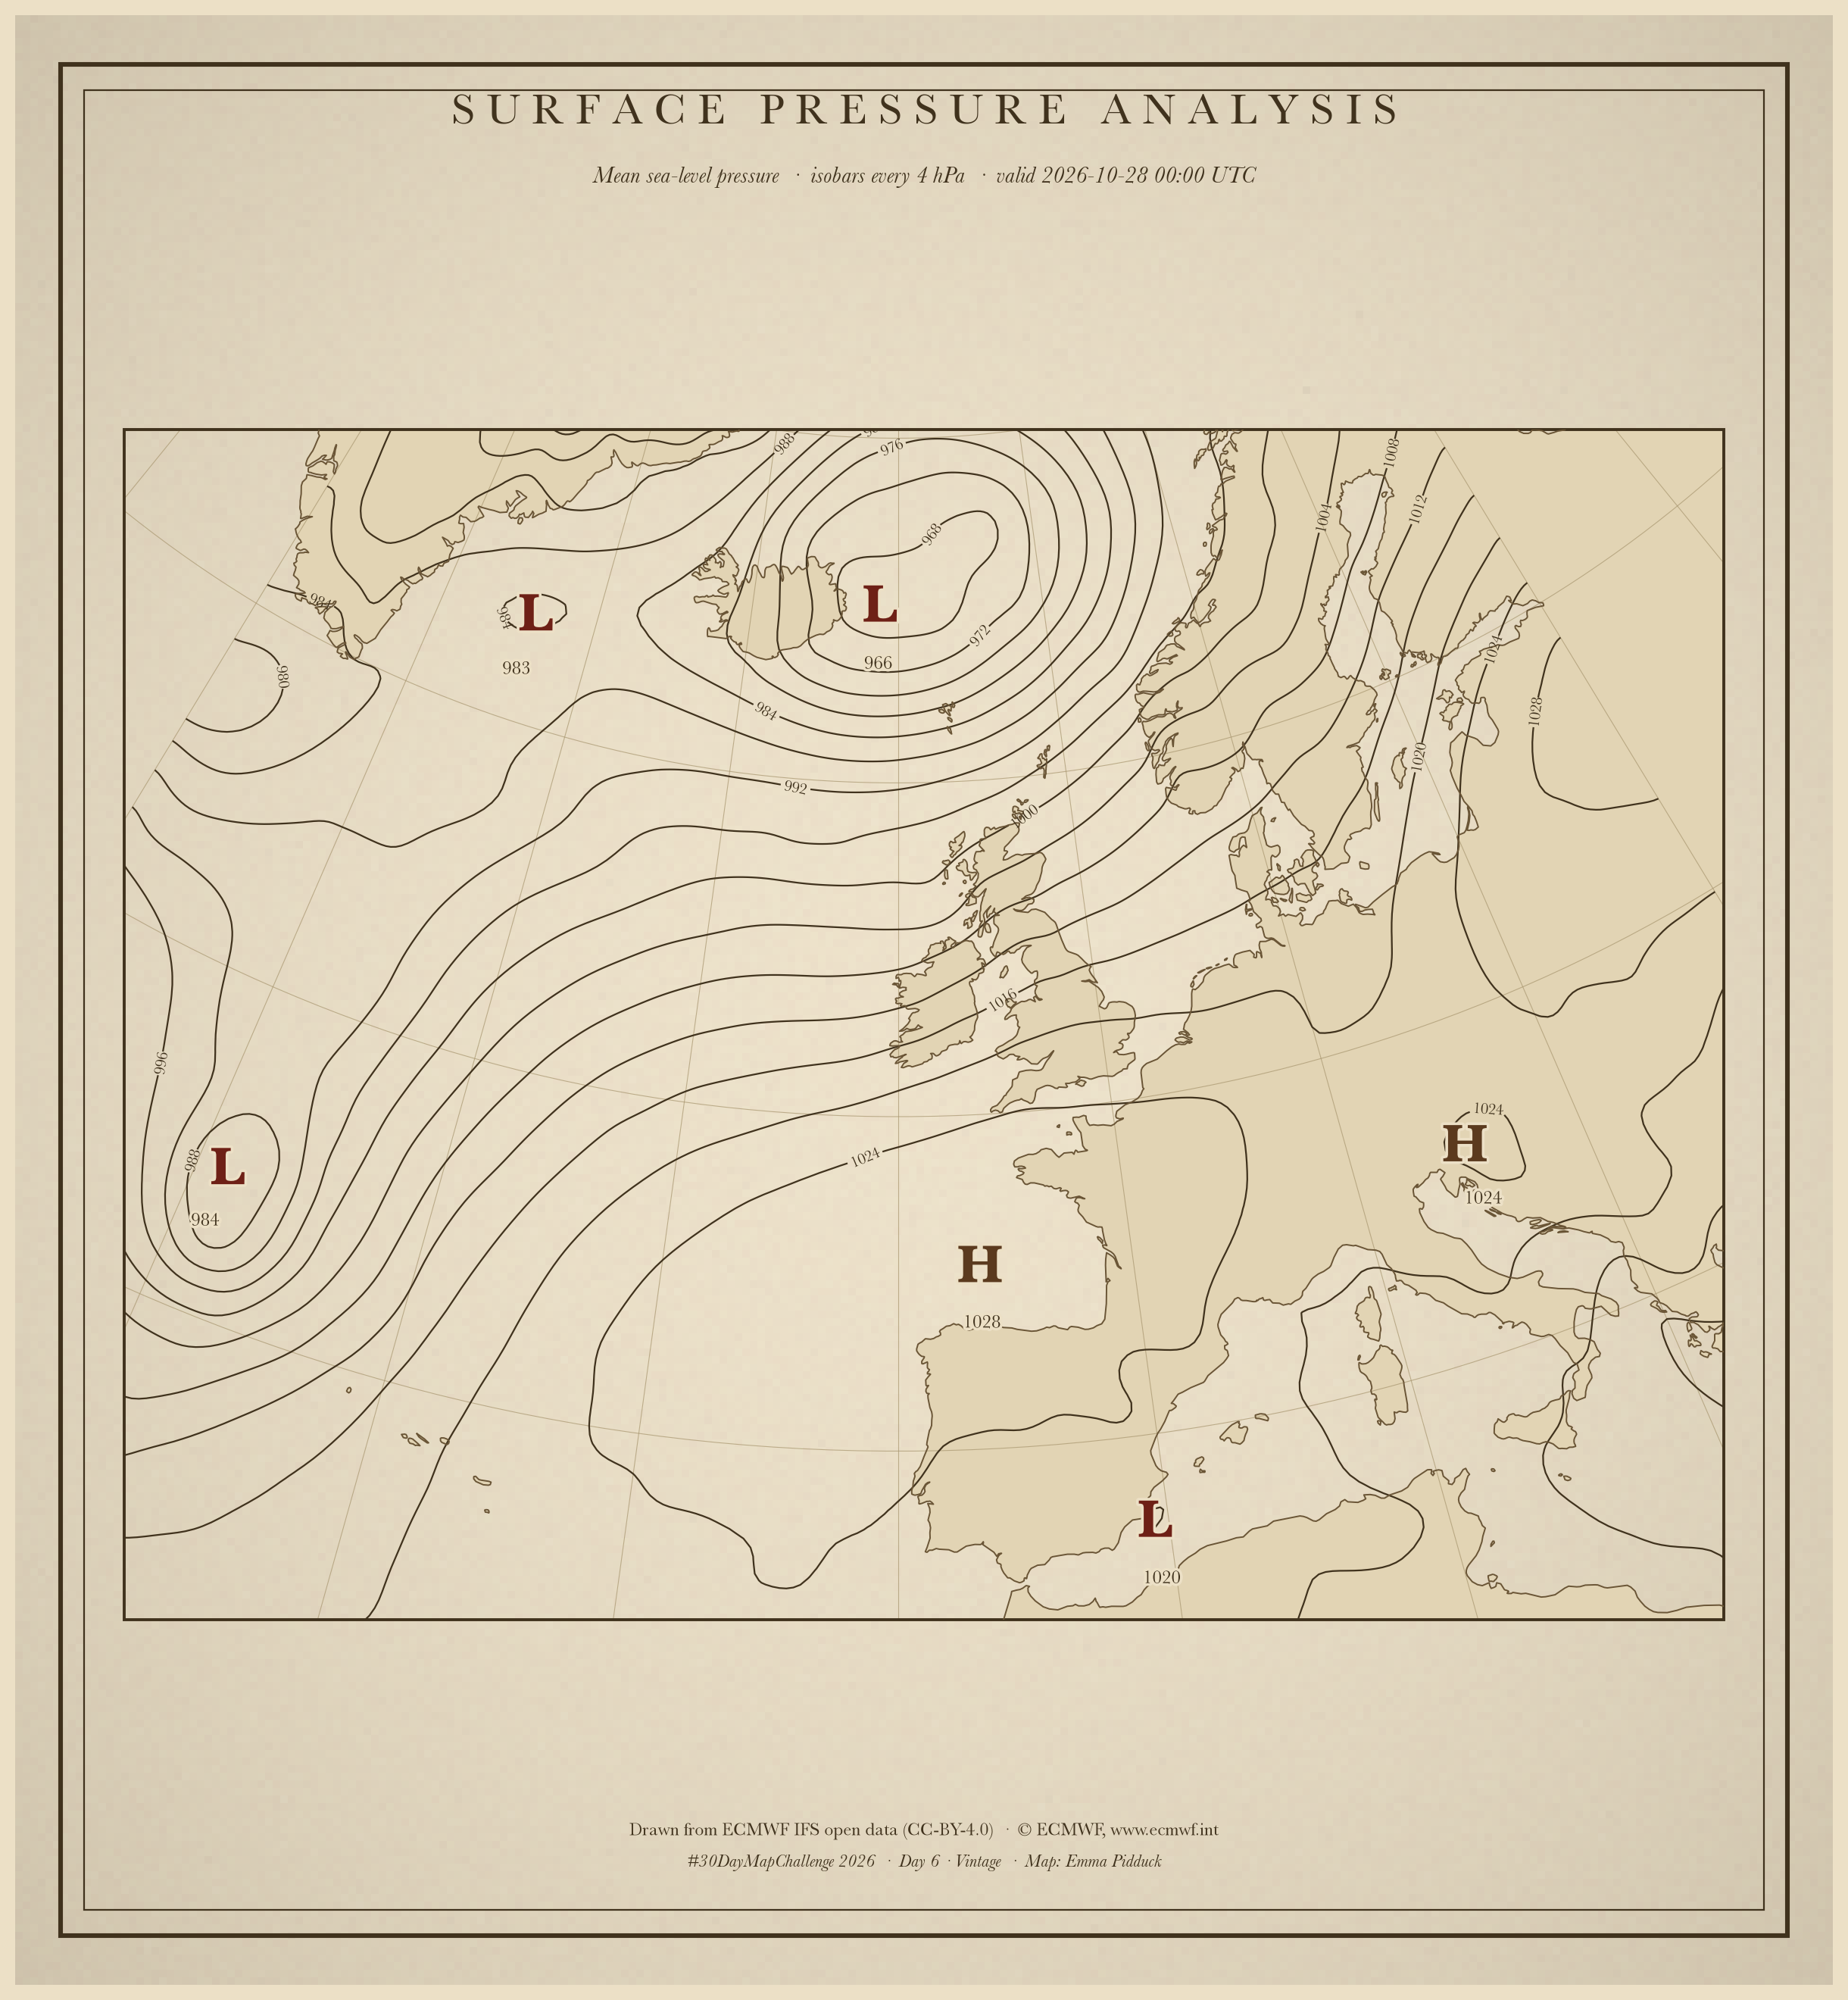

In [7]:
proj = ccrs.LambertConformal(central_longitude=-10, central_latitude=52, standard_parallels=(40, 62))
tp = dict(transform=ccrs.PlateCarree())
fig = plt.figure(figsize=(12, 13), dpi=200); fig.patch.set_facecolor(PAPER)

# aged-paper grain + soft vignette on a full-figure background axes
bg = fig.add_axes([0, 0, 1, 1], zorder=-5); bg.axis("off")
rng = np.random.default_rng(6)
bg.imshow(rng.normal(0.5, 0.5, (260, 240)), cmap="pink", alpha=0.05,
          extent=[0, 1, 0, 1], aspect="auto", zorder=-5)
yy, xx = np.mgrid[0:1:260j, 0:1:240j]
bg.imshow((xx-0.5)**2 + (yy-0.5)**2, cmap="gray_r", alpha=0.12,
          extent=[0, 1, 0, 1], aspect="auto", zorder=-4)

ax = fig.add_axes([0.06, 0.105, 0.88, 0.765], projection=proj)
ax.set_extent(EXTENT, crs=ccrs.PlateCarree()); ax.set_facecolor("none")
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#e2d4b4", zorder=0)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=COAST, linewidth=0.7, zorder=3)
ax.gridlines(color=FAINT, linewidth=0.4, alpha=0.7, xlocs=range(-60, 41, 10),
             ylocs=range(20, 81, 10), zorder=1)

levels = np.arange(np.floor(msl.min()/4)*4, np.ceil(msl.max()/4)*4 + 4, 4)
cs = ax.contour(lon, lat, msl, levels=levels, colors=INK, linewidths=0.8, zorder=2, **tp)
for t in ax.clabel(cs, inline=True, fontsize=7.5, fmt="%d", colors=INK):
    t.set_fontfamily("serif")

halo = [pe.withStroke(linewidth=2.6, foreground=PAPER)]
for lonc, latc, val in highs:
    ax.text(lonc, latc, "H", color="#5b3a1e", fontsize=26, fontweight="bold", ha="center",
            va="center", path_effects=halo, zorder=5, **tp)
    ax.text(lonc, latc-1.7, f"{val:.0f}", color=INK, fontsize=9, ha="center", va="center",
            path_effects=halo, zorder=5, **tp)
for lonc, latc, val in lows:
    ax.text(lonc, latc, "L", color="#6e2016", fontsize=26, fontweight="bold", ha="center",
            va="center", path_effects=halo, zorder=5, **tp)
    ax.text(lonc, latc-1.7, f"{val:.0f}", color=INK, fontsize=9, ha="center", va="center",
            path_effects=halo, zorder=5, **tp)
ax.spines["geo"].set_edgecolor(INK); ax.spines["geo"].set_linewidth(1.4)

for lw, inset in [(2.2, 0.025), (0.8, 0.038)]:          # ruled double border
    fig.add_artist(plt.Rectangle((inset, inset), 1-2*inset, 1-2*inset, fill=False,
                   edgecolor=INK, linewidth=lw, transform=fig.transFigure, zorder=10))

fig.text(0.5, 0.945, "S U R F A C E   P R E S S U R E   A N A L Y S I S", ha="center",
         color=INK, fontsize=21, family="serif")
fig.text(0.5, 0.915, f"Mean sea-level pressure  ·  isobars every 4 hPa  ·  valid {VALID}",
         ha="center", color=INK, fontsize=11, family="serif", style="italic")
fig.text(0.5, 0.076, "Drawn from ECMWF IFS open data (CC-BY-4.0)  ·  © ECMWF, www.ecmwf.int",
         ha="center", color=INK, fontsize=8.5, family="serif")
fig.text(0.5, 0.060, "#30DayMapChallenge 2026  ·  Day 6 · Vintage  ·  Map: Emma Pidduck",
         ha="center", color=INK, fontsize=8.5, family="serif", style="italic")

fig.savefig("day06_vintage.png", facecolor=PAPER)
plt.show()

## Note

The deep low southeast of Iceland and the ridge over the Bay of Biscay are the real synoptic
situation at the valid time — the *analysis* is genuine, only the *look* is borrowed. Re-run
on any morning for that day's weather in the same hand.

**Saved:** `day06_vintage.png` — ready to post.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and MeteoSwiss) open data.
Day 2 is Lines (the jet); Day 20 Hexagons; Day 22 Projections.*